# 04b. Modèle du décrochage au primaire

Sentinelle Scolaire, défi 1.

La cible est le **taux d'abandon du primaire** de la province entre l'année t et t+1, pour l'ensemble des élèves et par sexe. Seules les cibles observées hors rupture de scolarisation servent à apprendre et à évaluer (notebook 04a).

Le modèle a trois briques :

1. **Prévision** du taux d'abandon à 1, 2 et 3 ans, avec un intervalle à 80 % calibré. Dix modèles sont comparés dans le temps ; le niveau habituel de la province est le modèle à battre : un autre n'est retenu que s'il réduit l'erreur d'au moins 3 % et gagne au moins deux plis sur trois. À défaut, un modèle qui suit la situation de l'année (retour amorti vers le niveau habituel, combinaison avec l'elastic net) est préféré s'il est aussi précis à 1 % près sur les plis de sélection. Le test final ne sert jamais au choix.

**Normalisation de la cible.** Les modèles apprennent sur z = logit(taux / 100) ; prévisions et intervalles sont dénormalisés (taux = 100 / (1 + e^(−z))), donc toujours entre 0 et 100 %. Les taux apparents négatifs (arrivées nettes d'élèves, ramenés à zéro par la DGESS) prennent la valeur plancher de 0,5 %.

**Optimisation sans fuite d'information.** Dans chaque pli, les variables sont classées par importance par permutation (mesurée sur la dernière année de l'apprentissage) et chaque modèle garde ses k premières ; k, les pénalités, les paramètres de LightGBM et le rétrécissement vers la région sont choisis sur les plis de sélection. Le modèle final garde les variables retenues dans au moins la moitié des plis.
2. **Explication** : pourquoi une province a un niveau habituel d'abandon élevé (contribution de chaque variable, en points de taux).
3. **Alerte de rupture** : risque que la scolarisation s'effondre (variation des effectifs de plus de 30 %).

**Validation dans le temps.** Pour une cible de l'année Y, l'apprentissage n'utilise que des cibles connues à la date des variables. Trois plis servent aux choix ; le test final (2024-2025 pour l'ensemble, 2023-2024 par sexe) n'est utilisé qu'une fois.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentinelle.analyse import executer_exploration, executer_modelisation

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#bdbcb6",
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.labelcolor": "#52514e"})
SOURCE = "Source : annuaires DGESS, base apurée du défi 1. Calculs des auteurs."
COULEURS = {"reference_annee_precedente": "#bdbcb6", "reference_niveau_habituel": "#1f3a5f",
            "reference_niveau_retreci": "#6c8fb3",
            "elastic_net": "#2e9e55", "ridge_effet_province": "#8a8984", "lightgbm": "#e8935a",
            "moyenne_elastic_lightgbm": "#b5446e", "retour_amorti": "#d4a017"}

In [2]:
executer_exploration()
tables = executer_modelisation()

## 1. Brique 1 : quel modèle prévoit le mieux ?

Erreur absolue moyenne (points de taux), corrélation de rang entre taux prévus et observés, et part des provinces du quintile le plus à risque effectivement retrouvées. Les modèles appris prédisent l'écart au niveau habituel de la province, diminué du choc commun à toutes les provinces l'année de la cible (une crise nationale n'est prévisible par aucune variable provinciale).

In [3]:
s = tables["synthese_modeles_ensemble"]
s[s["horizon"] == 1].pivot_table(index="modele", columns="role",
                                 values=["erreur_absolue_moyenne", "correlation_rang", "rappel_quintile_le_plus_a_risque"])

correlation_rang            erreur_absolue_moyenne            rappel_quintile_le_plus_a_risque           
role                              sélection test final              sélection test final                        sélection test final
modele                                                                                                                              
combinaison_niveau_elastic            0.541      0.557                  6.306      3.412                            0.548      0.750
elastic_net                           0.539      0.557                  6.289      3.419                            0.548      0.750
lightgbm                              0.571      0.550                  6.185      4.348                            0.500      0.750
lightgbm_elimination                  0.552      0.478                  6.433      5.099                            0.548      0.750
moyenne_elastic_lightgbm              0.562      0.537                  6.181      3.758                            0.500      0.750
reference_annee_precedente            0.340      0.365                  7.767      4.442                            0.506      0.625
reference_niveau_habituel             0.541      0.557                  6.323      3.406                            0.548      0.750
reference_niveau_retreci              0.518      0.617                  6.271      3.614                            0.464      0.625
retour_amorti                         0.489      0.549                  6.271      3.339                            0.548      0.750
ridge_effet_province                  0.462      0.526                  7.000      3.427                            0.458      0.750

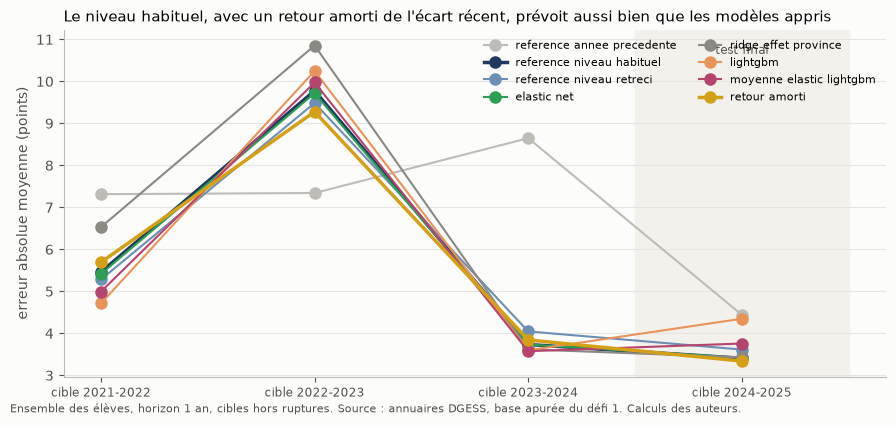

In [4]:
e = tables["evaluation_plis_ensemble"]
e1 = e[e["horizon"] == 1]
fig, ax = plt.subplots(figsize=(9, 4.2))
annees = sorted(e1["annee_cible"].unique())
for m, couleur in COULEURS.items():
    serie = e1[e1["modele"] == m].set_index("annee_cible")["erreur_absolue_moyenne"].reindex(annees)
    ax.plot(range(len(annees)), serie.values, marker="o", ms=8, lw=2.5 if m in ("reference_niveau_habituel", "retour_amorti") else 1.5,
            color=couleur, label=m.replace("_", " "))
ax.axvspan(len(annees) - 1.5, len(annees) - 0.5, color="#f2f1ec", zorder=0)
ax.text(len(annees) - 1, ax.get_ylim()[1] * 0.97, "test final", ha="center", va="top", fontsize=8.5, color="#52514e")
ax.set_xticks(range(len(annees)), [f"cible {a}" for a in annees], fontsize=8.5)
ax.set_ylabel("erreur absolue moyenne (points)")
ax.grid(axis="y", color="#e6e5e0")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
ax.set_title("Le niveau habituel, avec un retour amorti de l'écart récent, prévoit aussi bien que les modèles appris", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Ensemble des élèves, horizon 1 an, cibles hors ruptures. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

**Lecture.** Même optimisés (normalisation logit, sélection des variables dans chaque pli, réglages), les modèles appris gagnent un peu les années de crise et perdent les années calmes ; aucun ne réduit l'erreur d'au moins 3 % de façon régulière par rapport au niveau habituel de la province (moyenne de ses taux passés hors ruptures). Le retour amorti, qui part du niveau habituel et laisse l'écart de la dernière année se résorber d'un facteur φ par an (φ choisi sur les plis de sélection), est aussi précis à 1 % près sur ces plis : il est retenu, car il exploite la situation de l'année et donne une trajectoire qui revient progressivement vers le niveau habituel. Le même constat vaut par sexe :

In [5]:
s = tables["synthese_modeles_sexe"]
s[s["horizon"] == 1].pivot_table(index="modele", columns="role", values=["erreur_absolue_moyenne", "correlation_rang"])

correlation_rang            erreur_absolue_moyenne           
role                              sélection test final              sélection test final
modele                                                                                  
combinaison_niveau_elastic            0.549      0.660                  6.331      3.830
elastic_net                           0.549      0.660                  6.321      3.829
lightgbm                              0.511      0.639                  6.488      4.126
lightgbm_elimination                  0.528      0.694                  6.321      3.396
moyenne_elastic_lightgbm              0.531      0.656                  6.365      3.891
reference_annee_precedente            0.328      0.484                  7.112      8.725
reference_niveau_habituel             0.549      0.660                  6.340      3.832
reference_niveau_retreci              0.512      0.523                  6.195      4.249
retour_amorti                         0.479      0.557                  6.318      4.147
ridge_effet_province                  0.521      0.414                  7.274      4.867

In [6]:
pd.concat({"ensemble": tables["reglages_ensemble"], "par sexe": tables["reglages_sexe"]})

,,kappa,phi,alpha_elastic,k_elastic,alpha_ridge,k_ridge,lightgbm,k_lightgbm,modele_retenu
ensemble,0,4.0,0.2,0.3,None,1000.0,5,0,15,retour_amorti
par sexe,0,8.0,0.3,0.3,5,1000.0,5,2,None,retour_amorti


Variables retenues par LightGBM dans les plis (horizon 1 an) : part des plis où chacune figure parmi les k premières.

In [7]:
v = tables["variables_retenues_ensemble"]
v[(v["horizon"] == 1) & (v["modele"] == "lightgbm")].head(15)

,modele,variable,part_des_plis,horizon
52,lightgbm,part_etab_post_primaire_secondaire_publics_electricite_region,1.00,1
53,lightgbm,part_ecoles_primaires_cycle_incomplet,1.00,1
54,lightgbm,abandons_primaire_orpaillage_pour_1000_region,0.75,1
55,lightgbm,part_cp1,0.75,1
56,lightgbm,evolution_eleves_primaire,0.50,1
57,lightgbm,abandon_primaire_precedent,0.50,1
58,lightgbm,moyenne_passee_abandon,0.50,1
59,lightgbm,part_enseignants_primaire_debutants,0.50,1
60,lightgbm,part_ecoles_primaires_electricite,0.50,1
61,lightgbm,deficit_places_pour_100_eleves_primaire,0.50,1


### Élimination récursive guidée par SHAP

Dans chaque pli, LightGBM est appris sur les variables restantes, les 10 % les moins importantes (contribution SHAP absolue moyenne) sont retirées, et l'erreur est mesurée sur la dernière année de l'apprentissage. Le nombre de variables retenu est le plus petit dont l'erreur reste à moins de 1 % de la meilleure ; le pli de test mesure ensuite le modèle ainsi réduit (modèle `lightgbm_elimination`).

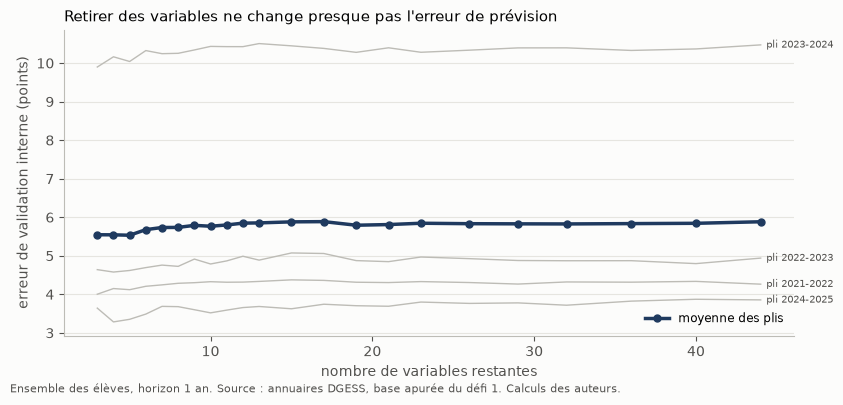

In [8]:
c = tables["courbe_elimination_prevision_ensemble"]
c = c[c["horizon"] == 1]
large = c.pivot_table(index="nombre_de_variables", columns="annee_cible", values="erreur_validation_interne")
fig, ax = plt.subplots(figsize=(8.5, 4))
for annee in large.columns:
    ax.plot(large.index, large[annee], color="#bdbcb6", lw=1)
    ax.annotate(f"pli {annee}", (large.index[-1], large[annee].iloc[-1]), xytext=(4, 0),
                textcoords="offset points", fontsize=7.5, color="#52514e", va="center")
moyenne = large.mean(axis=1)
ax.plot(moyenne.index, moyenne.values, color="#1f3a5f", lw=2.5, marker="o", ms=5, label="moyenne des plis")
ax.set_xlabel("nombre de variables restantes")
ax.set_ylabel("erreur de validation interne (points)")
ax.grid(axis="y", color="#e6e5e0"); ax.legend(frameon=False, fontsize=8.5)
ax.set_title("Retirer des variables ne change presque pas l'erreur de prévision", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Ensemble des élèves, horizon 1 an. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

In [9]:
e = tables["evaluation_plis_ensemble"]
e[e["horizon"] == 1].pivot_table(index="modele", columns="annee_cible", values="erreur_absolue_moyenne").round(2)

annee_cible,2021-2022,2022-2023,2023-2024,2024-2025
modele,,,,
combinaison_niveau_elastic,5.44,9.75,3.73,3.41
elastic_net,5.42,9.72,3.73,3.42
lightgbm,4.71,10.25,3.60,4.35
lightgbm_elimination,6.28,9.38,3.64,5.10
moyenne_elastic_lightgbm,4.99,9.97,3.57,3.76
reference_annee_precedente,7.31,7.34,8.65,4.44
reference_niveau_habituel,5.46,9.78,3.73,3.41
reference_niveau_retreci,5.28,9.48,4.05,3.61
retour_amorti,5.69,9.28,3.84,3.34


In [10]:
e = tables["evaluation_plis_sexe"]
e[e["horizon"] == 1].pivot_table(index="modele", columns="annee_cible", values="erreur_absolue_moyenne").round(2)

annee_cible,2020-2021,2021-2022,2022-2023,2023-2024
modele,,,,
combinaison_niveau_elastic,3.85,5.38,9.76,3.83
elastic_net,3.86,5.36,9.74,3.83
lightgbm,4.28,4.82,10.37,4.13
lightgbm_elimination,4.13,4.78,10.06,3.40
moyenne_elastic_lightgbm,4.07,5.04,9.98,3.89
reference_annee_precedente,7.66,6.29,7.39,8.72
reference_niveau_habituel,3.84,5.41,9.78,3.83
reference_niveau_retreci,3.94,5.24,9.41,4.25
retour_amorti,4.19,5.74,9.03,4.15


## 2. L'intervalle à 80 %

La marge est calibrée sur l'échelle logit à partir des erreurs hors échantillon des plis (prédiction conforme), puis dénormalisée : l'intervalle est asymétrique, plus étroit vers 0, et ne sort jamais de [0 ; 100]. La couverture est mesurée sur le test final, jamais utilisé avant ; elle doit être proche de 80 % ou au-dessus. L'intervalle reste large parce que les plis comprennent les années de crise 2021-2023.

In [11]:
pd.concat({"ensemble": tables["intervalle_ensemble"], "par sexe": tables["intervalle_sexe"]})

horizon         modele  marge_conforme_logit  couverture_test_final  largeur_moyenne_points  lignes
ensemble 0        1  retour_amorti                 0.990                  0.850                  19.187      40
         1        2  retour_amorti                 1.004                  0.875                  20.386      40
         2        3  retour_amorti                 1.004                  0.850                  18.518      40
par sexe 0        1  retour_amorti                 1.072                  0.859                  21.618      64
         1        2  retour_amorti                 1.192                  0.938                  20.991      64
         2        3  retour_amorti                 1.192                  0.922                  19.439      64

## 3. Les prévisions 2025-2026

Classe de risque : *élevé* au-dessus du 80e centile des taux observés, *moyen* au-dessus de la médiane.

In [12]:
tables["seuils_classes_ensemble"]

,classe,taux_abandon_prevu
0,moyen à partir de (médiane),8.43
1,élevé à partir de (80e centile),14.16


In [13]:
tb = tables["tableau_de_bord_ensemble"]
tb[["province_nom", "region_nom", "taux_abandon_annee_des_variables", "taux_abandon_prevu", "borne_basse_80",
    "borne_haute_80", "classe_de_risque", "risque_de_rupture", "province_scindee"]].head(20)

,province_nom,region_nom,taux_abandon_annee_des_variables,taux_abandon_prevu,borne_basse_80,borne_haute_80,classe_de_risque,risque_de_rupture,province_scindee
0,Loroum,Yaadga,34.350,27.08,13.10,47.80,élevé,élevé,False
1,Karo-Peli,Soum,18.680,23.55,11.11,43.15,élevé,élevé,True
2,Djelgodji,Soum,18.680,23.16,10.89,42.63,élevé,élevé,True
3,Seno,Liptako,18.310,22.96,10.78,42.35,élevé,élevé,False
4,Yagha,Liptako,19.370,22.77,10.68,42.09,élevé,élevé,False
5,Oudalan,Liptako,18.680,18.59,8.48,36.01,élevé,élevé,False
6,Kossin,Sourou,-1.370,16.25,7.30,32.35,élevé,faible,False
7,Namentenga,Koulse,17.180,15.88,7.11,31.76,élevé,moyen,False
8,Gobnangou,Tapoa,9.745,15.79,7.07,31.62,élevé,élevé,True
9,Dyamongou,Tapoa,9.745,15.79,7.07,31.62,élevé,élevé,True


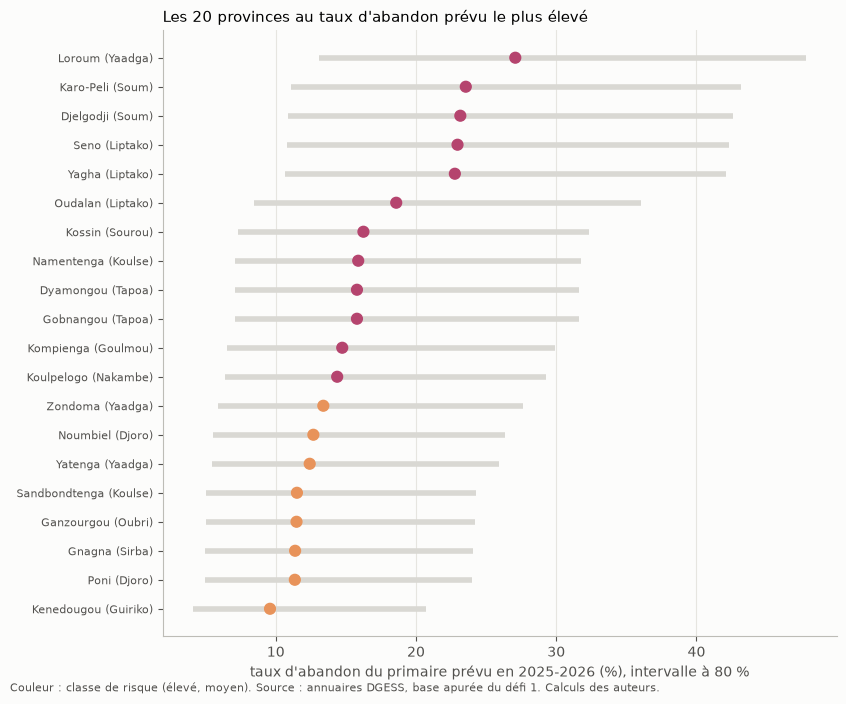

In [14]:
t = tb.sort_values("taux_abandon_prevu").tail(20)
fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(len(t))
couleur = t["classe_de_risque"].map({"élevé": "#b5446e", "moyen": "#e8935a", "faible": "#8a8984"})
ax.hlines(y, t["borne_basse_80"].clip(lower=0), t["borne_haute_80"], color="#d9d8d3", lw=4)
ax.scatter(t["taux_abandon_prevu"], y, color=couleur, s=60, zorder=3)
ax.set_yticks(y, t["province_nom"] + " (" + t["region_nom"] + ")", fontsize=8)
ax.set_xlabel("taux d'abandon du primaire prévu en 2025-2026 (%), intervalle à 80 %")
ax.grid(axis="x", color="#e6e5e0")
ax.set_title("Les 20 provinces au taux d'abandon prévu le plus élevé", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Couleur : classe de risque (élevé, moyen). " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 4. Brique 2 : pourquoi ces provinces ?

Le niveau habituel de chaque province est expliqué par ses variables moyennes (sans les variables de persistance). La qualité est mesurée en prédisant des provinces que le modèle n'a pas vues ; le modèle (LightGBM ou elastic net) et le nombre k de variables sont choisis sur cette mesure, le classement des variables étant refait dans chaque pli.

In [15]:
pd.concat({"ensemble": tables["explication_validation_ensemble"], "par sexe": tables["explication_validation_sexe"]})

modele   k  unites  r2_provinces_non_vues  correlation_rang_provinces_non_vues  erreur_absolue_moyenne                   role
ensemble 0              lightgbm   5      43                 0.4920                                0.807                  2.2930                       
         1              lightgbm   8      43                 0.4730                                0.743                  2.4980                       
         2              lightgbm  12      43                 0.4570                                0.734                  2.5840                       
         3              lightgbm  40      43                 0.4800                                0.740                  2.3130                       
         4           elastic_net   5      43                 0.6370                                0.804                  2.1600        effets chiffrés
         5           elastic_net   8      43                 0.5660                                0.783                  2.4600                       
         6           elastic_net  12      43                 0.4940                                0.705                  2.4740                       
         7           elastic_net  40      43                 0.3190                                0.745                  2.6510                       
         8  lightgbm_elimination   8      43                 0.5224                                  NaN                  2.4994  facteurs par province
par sexe 0              lightgbm   5      86                 0.2070                                0.636                  3.4800                       
         1              lightgbm   8      86                 0.2760                                0.717                  3.2600                       
         2              lightgbm  12      86                 0.4010                                0.764                  3.0510                       
         3              lightgbm  41      86                 0.4320                                0.759                  2.9060                       
         4           elastic_net   5      86                 0.4220                                0.716                  3.0170                       
         5           elastic_net   8      86                 0.4730                                0.748                  2.8950        effets chiffrés
         6           elastic_net  12      86                -0.7300                                0.748                  3.6250                       
         7           elastic_net  41      86                 0.3070                                0.727                  3.0450                       
         8  lightgbm_elimination  20      86                 0.4481                                  NaN                  2.9679  facteurs par province

Courbe d'élimination récursive (LightGBM guidé par SHAP) pour l'explication : part de variance expliquée des provinces non vues selon le nombre de variables, comparée au meilleur elastic net.

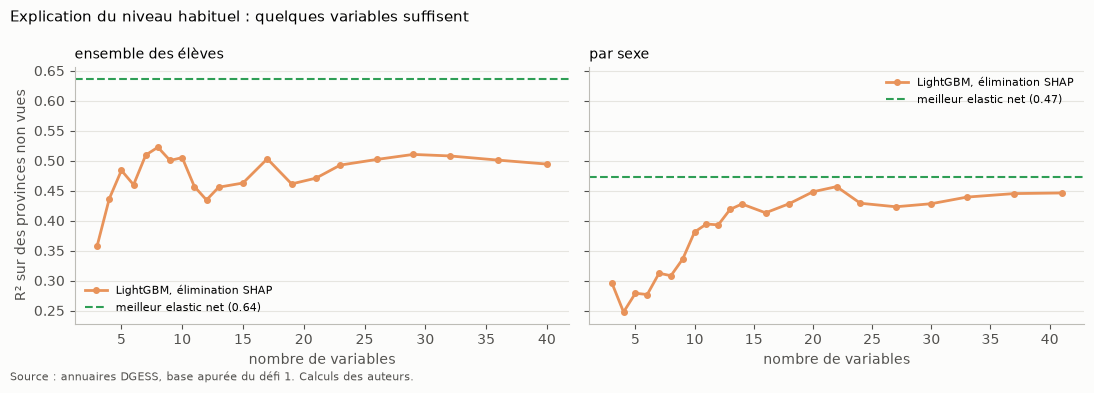

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, nom, titre in zip(axes, ["ensemble", "sexe"], ["ensemble des élèves", "par sexe"]):
    c = tables[f"explication_courbe_elimination_{nom}"]
    v = tables[f"explication_validation_{nom}"]
    ax.plot(c["nombre_de_variables"], c["r2_provinces_non_vues"], color="#e8935a", lw=2, marker="o", ms=4,
            label="LightGBM, élimination SHAP")
    meilleur = v[v["modele"] == "elastic_net"]["r2_provinces_non_vues"].max()
    ax.axhline(meilleur, color="#2e9e55", lw=1.5, ls="--", label=f"meilleur elastic net ({meilleur:.2f})")
    ax.set_xlabel("nombre de variables"); ax.set_title(titre, loc="left", fontsize=10)
    ax.grid(axis="y", color="#e6e5e0"); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("R² sur des provinces non vues")
fig.suptitle("Explication du niveau habituel : quelques variables suffisent", x=0.01, ha="left", fontsize=11)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

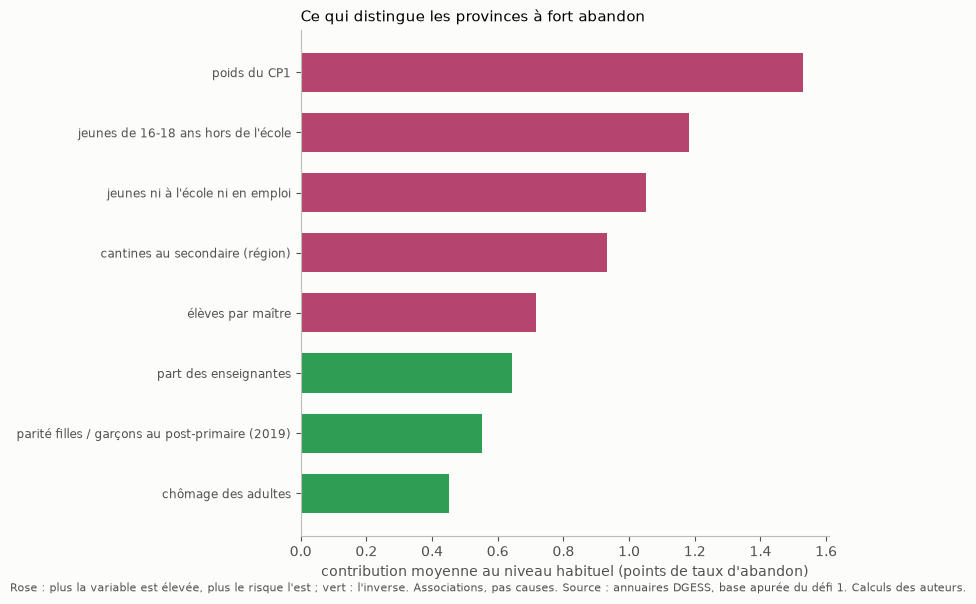

In [17]:
imp = tables["explication_importance_ensemble"].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6))
couleur = imp["sens"].map(lambda s: "#b5446e" if "plus le risque est élevé" in s else
                          ("#2e9e55" if "plus le risque est faible" in s else "#8a8984"))
ax.barh(imp["libelle"], imp["contribution_absolue_moyenne_points"], color=couleur, height=0.65)
ax.set_xlabel("contribution moyenne au niveau habituel (points de taux d'abandon)")
ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("Ce qui distingue les provinces à fort abandon", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Rose : plus la variable est élevée, plus le risque l'est ; vert : l'inverse. "
         "Associations, pas causes. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

In [18]:
tables["explication_importance_ensemble"].head(15)

,variable,libelle,contribution_absolue_moyenne_points,sens
0,part_cp1,poids du CP1,1.531,"plus elle est élevée, plus le risque est élevé"
1,hors_ecole_16_18_province,jeunes de 16-18 ans hors de l'école,1.183,"plus elle est élevée, plus le risque est élevé"
2,ni_ecole_ni_emploi_15_24_province,jeunes ni à l'école ni en emploi,1.052,"plus elle est élevée, plus le risque est élevé"
3,part_etab_post_primaire_secondaire_publics_cantine_region,cantines au secondaire (région),0.932,"plus elle est élevée, plus le risque est élevé"
4,eleves_par_maitre_primaire,élèves par maître,0.717,"plus elle est élevée, plus le risque est élevé"
5,part_enseignantes_primaire,part des enseignantes,0.644,"plus elle est élevée, plus le risque est faible"
6,parite_scolarisation_post_primaire_province,parité filles / garçons au post-primaire (2019),0.553,"plus elle est élevée, plus le risque est faible"
7,chomage_25_64_province,chômage des adultes,0.452,"plus elle est élevée, plus le risque est faible"


Effet de chaque variable retenue, dénormalisé : en points de taux d'abandon pour un point de pourcentage (parts) ou une unité de la variable.

In [19]:
tables["explication_effets_lineaires_ensemble"]

,variable,libelle,effet_pour_un_ecart_type_points,ecart_type_de_la_variable,unite,effet_par_unite_points
0,part_cp1,poids du CP1,3.220,0.0331,point de pourcentage,0.9717
1,ni_ecole_ni_emploi_15_24_province,jeunes ni à l'école ni en emploi,0.958,12.2366,unité de la variable,0.0783
2,deficit_places_pour_100_eleves_primaire,déficit de places assises,0.701,4.4759,unité de la variable,0.1565


In [20]:
tb[["province_nom", "taux_abandon_prevu", "facteur_1", "facteur_2", "facteur_3", "frein_principal"]].head(15)

,province_nom,taux_abandon_prevu,facteur_1,facteur_2,facteur_3,frein_principal
0,Loroum,27.08,poids du CP1 (+3.2 pt),jeunes de 16-18 ans hors de l'école (+2.8 pt),jeunes ni à l'école ni en emploi (+2.4 pt),chômage des adultes (-0.3 pt)
1,Karo-Peli,23.55,poids du CP1 (+3.2 pt),jeunes ni à l'école ni en emploi (+2.6 pt),jeunes de 16-18 ans hors de l'école (+2.4 pt),part des enseignantes (-1.4 pt)
2,Djelgodji,23.16,poids du CP1 (+3.2 pt),jeunes ni à l'école ni en emploi (+2.6 pt),jeunes de 16-18 ans hors de l'école (+2.4 pt),part des enseignantes (-1.4 pt)
3,Seno,22.96,poids du CP1 (+3.2 pt),jeunes ni à l'école ni en emploi (+2.6 pt),jeunes de 16-18 ans hors de l'école (+2.4 pt),chômage des adultes (-0.3 pt)
4,Yagha,22.77,poids du CP1 (+2.9 pt),jeunes ni à l'école ni en emploi (+2.5 pt),jeunes de 16-18 ans hors de l'école (+2.2 pt),élèves par maître (-0.9 pt)
5,Oudalan,18.59,poids du CP1 (+3.1 pt),jeunes ni à l'école ni en emploi (+2.5 pt),jeunes de 16-18 ans hors de l'école (+2.4 pt),part des enseignantes (-1.4 pt)
6,Kossin,16.25,jeunes de 16-18 ans hors de l'école (+2.6 pt),poids du CP1 (+1.5 pt),parité filles / garçons au post-primaire (2019) (+1.2 pt),cantines au secondaire (région) (-0.8 pt)
7,Namentenga,15.88,poids du CP1 (+2.9 pt),jeunes ni à l'école ni en emploi (+2.6 pt),cantines au secondaire (région) (+2.2 pt),part des enseignantes (-1.5 pt)
8,Gobnangou,15.79,poids du CP1 (+1.7 pt),parité filles / garçons au post-primaire (2019) (+1.2 pt),part des enseignantes (+1.1 pt),cantines au secondaire (région) (-0.7 pt)
9,Dyamongou,15.79,jeunes de 16-18 ans hors de l'école (+2.6 pt),poids du CP1 (+1.6 pt),parité filles / garçons au post-primaire (2019) (+1.2 pt),cantines au secondaire (région) (-0.8 pt)


## 5. Par sexe

In [21]:
tables["explication_importance_sexe"].head(12)

,variable,libelle,contribution_absolue_moyenne_points,sens
0,hors_ecole_16_18_province,jeunes de 16-18 ans hors de l'école,1.198,"plus elle est élevée, plus le risque est élevé"
1,rapport_cm2_cp1,rapport CM2 / CP1,0.898,"plus elle est élevée, plus le risque est faible"
2,achevement_post_primaire_province,achèvement du post-primaire,0.821,"plus elle est élevée, plus le risque est faible"
3,parite_scolarisation_post_primaire_province,parité filles / garçons au post-primaire (2019),0.531,"plus elle est élevée, plus le risque est faible"
4,eleves_par_maitre_primaire,élèves par maître,0.527,"plus elle est élevée, plus le risque est élevé"
5,achevement_primaire_province,achèvement du primaire,0.454,"plus elle est élevée, plus le risque est faible"
6,ips_tbs_primaire_region,parité de scolarisation (région),0.399,"plus elle est élevée, plus le risque est faible"
7,abandons_primaire_orpaillage_pour_1000_region,abandons pour l'orpaillage (région),0.359,"plus elle est élevée, plus le risque est élevé"
8,part_eleves_primaire_12_ans_et_plus,élèves de 12 ans et plus,0.353,"plus elle est élevée, plus le risque est faible"
9,fille,fille,0.322,"plus elle est élevée, plus le risque est faible"


In [22]:
tables["explication_effets_lineaires_sexe"]

,variable,libelle,effet_pour_un_ecart_type_points,ecart_type_de_la_variable,unite,effet_par_unite_points
0,achevement_post_primaire_province,achèvement du post-primaire,-1.872,14.0512,unité de la variable,-0.1332
1,part_eleves_primaire_12_ans_et_plus,élèves de 12 ans et plus,-1.729,0.0301,point de pourcentage,-0.5737
2,eleves_par_maitre_primaire,élèves par maître,1.595,7.3401,unité de la variable,0.2173
3,ips_tbs_primaire_region,parité de scolarisation (région),-0.953,0.0298,unité de la variable,-31.9656
4,rapport_cm2_cp1,rapport CM2 / CP1,-0.784,0.1573,unité de la variable,-4.9867
5,parite_scolarisation_post_primaire_province,parité filles / garçons au post-primaire (2019),-0.396,0.1684,unité de la variable,-2.3530
6,achevement_primaire_province,achèvement du primaire,-0.387,22.0337,unité de la variable,-0.0176


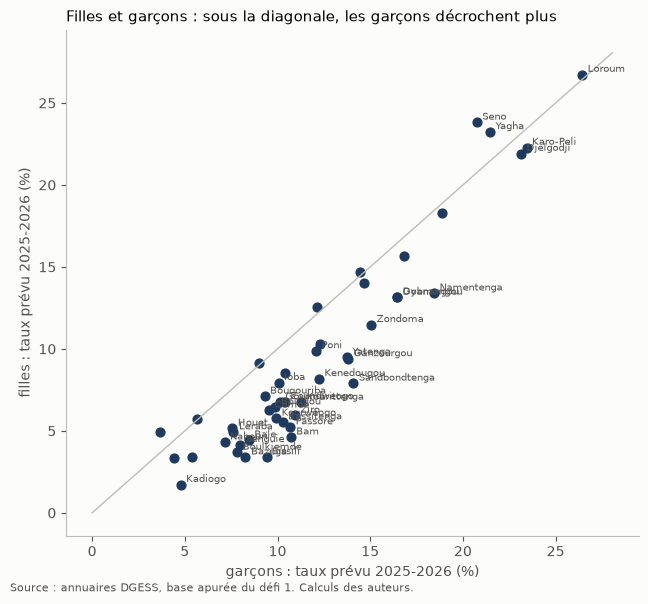

In [23]:
ts = tables["tableau_de_bord_sexe"]
large = ts.pivot_table(index="province_nom", columns="sexe", values="taux_abandon_prevu")
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(large["G"], large["F"], color="#1f3a5f", s=40)
borne = [0, max(large.max()) * 1.05]
ax.plot(borne, borne, color="#bdbcb6", lw=1)
for nom, r in large.iterrows():
    if abs(r["F"] - r["G"]) > 2 or r.max() > 20:
        ax.annotate(nom, (r["G"], r["F"]), xytext=(4, 2), textcoords="offset points", fontsize=7.5, color="#52514e")
ax.set_xlabel("garçons : taux prévu 2025-2026 (%)"); ax.set_ylabel("filles : taux prévu 2025-2026 (%)")
ax.set_title("Filles et garçons : sous la diagonale, les garçons décrochent plus", loc="left", fontsize=11)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 6. Brique 3 : l'alerte de rupture

Régression logistique pénalisée sur des signaux connus à la date t. Mesure : AUC (probabilité qu'une province en rupture ait un score plus élevé qu'une autre) et nombre de ruptures retrouvées dans le quart des provinces au score le plus élevé.

In [24]:
tables["evaluation_alerte_rupture"]

,annee_cible,role,provinces,ruptures,auc,ruptures_dans_le_quart_le_plus_a_risque
0,2021-2022,sélection,43,5,0.874,4
1,2022-2023,sélection,40,8,0.852,7
2,2023-2024,sélection,34,2,0.906,2
3,2024-2025,test final,42,2,0.962,2


In [25]:
tables["coefficients_alerte_rupture"]

,variable,libelle,coefficient_standardise
6,hors_ecole_16_18_province,jeunes de 16-18 ans hors de l'école,1.326
0,evolution_eleves_primaire,évolution des effectifs,-1.044
2,rupture_annee_precedente,rupture l'année précédente,-0.923
4,abandon_primaire_precedent,abandon de l'année,0.905
3,ruptures_passees,ruptures passées,0.422
5,abandons_primaire_orpaillage_pour_1000_region,abandons pour l'orpaillage (région),-0.406
1,baisse_effectifs,baisse des effectifs,-0.008


In [26]:
tables["alerte_rupture"].head(15)

,province_pcode,province_nom,region_nom,annee_prevue,score_rupture,risque_de_rupture
0,BF5902,Karo-Peli,Soum,2025-2026,0.995,élevé
1,BF6403,Yagha,Liptako,2025-2026,0.994,élevé
2,BF5901,Djelgodji,Soum,2025-2026,0.983,élevé
3,BF5401,Loroum,Yaadga,2025-2026,0.966,élevé
4,BF5802,Komandjari,Sirba,2025-2026,0.923,élevé
5,BF6402,Seno,Liptako,2025-2026,0.904,élevé
6,BF6001,Dyamongou,Tapoa,2025-2026,0.903,élevé
7,BF6401,Oudalan,Liptako,2025-2026,0.871,élevé
8,BF5801,Gnagna,Sirba,2025-2026,0.811,élevé
9,BF6002,Gobnangou,Tapoa,2025-2026,0.783,élevé


## Ce qu'il faut retenir

- **Le décrochage est structurel et persistant.** Le niveau habituel de la province est la base de toute bonne prévision ; les modèles appris, même optimisés, ne font pas mieux durablement en validation dans le temps. On retient le retour amorti vers ce niveau, aussi précis et plus informatif, avec un intervalle à 80 % asymétrique, toujours entre 0 et 100 %, qui ne rétrécit pas avec l'horizon et dont la couverture est vérifiée sur le test final.
- **Peu de variables expliquent l'essentiel des écarts entre provinces** : poids du CP1 (élèves perdus au fil du cycle), jeunes ni à l'école ni en emploi, déficit de places assises ; par sexe, retard scolaire, achèvement du post-primaire, élèves par maître, parité. Ce sont des leviers de long terme.
- **La rupture est conjoncturelle et se prévoit** : l'alerte retrouve la plupart des ruptures dans le quart des provinces les plus à risque (AUC de 0,85 à 0,96).
- **Les garçons décrochent plus que les filles** au primaire dans la plupart des provinces.

Les tables `tableau_de_bord_ensemble.csv` et `tableau_de_bord_sexe.csv` alimentent la carte et les fiches de l'étape 05.